![image.png](https://i.imgur.com/a3uAqnb.png)

# GRPO with Verifiable Rewards on GSM8K

- **Dataset**: [GSM8K](https://huggingface.co/datasets/openai/gsm8k) from Hugging Face, 7,473 training and 1,319 test grade-school word problems, each with a numeric final answer
- **Task**: reinforcement learning post-training with verifiable rewards (a correct final number and a fixed answer format)
- **Model**: [unsloth/Qwen2.5-1.5B-Instruct](https://huggingface.co/unsloth/Qwen2.5-1.5B-Instruct) (1.5B parameters) loaded in 4-bit, fine-tuned with a rank-16 LoRA by TRL's `GRPOTrainer` through Unsloth
- **Runtime**: Colab T4 GPU

In this lab, we will:

- turn GSM8K into prompts with a reference answer and write three reward functions that check a completion with code, not with a reward model
- load a 4-bit instruct model with a LoRA adapter and a vLLM engine for fast sampling
- run the GRPO recipe with every configuration knob explained, and watch the reward curves
- measure accuracy and format rate on held-out problems before and after training
- compute the group-relative advantages of one prompt by hand and read them against the objective

## What is GRPO?

Group Relative Policy Optimization (GRPO) is a policy-gradient method for language models that needs no value network. For each prompt $q$ the current policy samples a group of $G$ completions $o_1, \dots, o_G$, a reward function scores each one, and the advantage of a completion is its reward measured against the rest of its group. Every token of a completion then shares that one advantage, and the update is the clipped PPO surrogate with an optional KL penalty to a frozen reference model.

$$\mathcal{J}(\theta)=\mathbb{E}\Big[\frac{1}{G}\sum_{i=1}^{G}\frac{1}{|o_i|}\sum_{t=1}^{|o_i|}\min\big(r_{i,t}\hat A_{i},\ \mathrm{clip}(r_{i,t},1-\varepsilon,1+\varepsilon)\,\hat A_{i}\big)\Big]-\beta\, D_{KL}\big(\pi_\theta\,\|\,\pi_{\text{ref}}\big),
\qquad
\hat A_{i}=\frac{R_i-\mathrm{mean}(\{R_j\}_{j=1}^{G})}{\mathrm{std}(\{R_j\}_{j=1}^{G})}$$

Where:
- $G$ is the group size, the number of completions sampled for one prompt (`num_generations` in TRL)
- $o_i$ is the $i$-th completion and $|o_i|$ its length in tokens
- $R_i$ is the total reward of completion $i$, here the sum of three programmatic checks
- $\hat A_i$ is the group-relative advantage, shared by every token of completion $i$
- $r_{i,t}$ is the probability ratio of token $t$ under the current policy and the policy that sampled it, and $\varepsilon$ is the clipping range
- $\beta$ weights the KL term to the reference policy $\pi_{\text{ref}}$ (the model before training), and $\beta = 0$ removes it

With a verifiable reward there is no reward model to over-optimise, which is why current recipes set $\beta = 0$, and TRL's default loss normalises over all tokens of the batch instead of over $|o_i|$.

Paper: [Shao et al., 2024. DeepSeekMath: Pushing the Limits of Mathematical Reasoning in Open Language Models](https://arxiv.org/abs/2402.03300)

## Setup

In Google Colab, select **Runtime > Change runtime type > T4 GPU**, then run the cells from top to bottom.

In [1]:
%%capture
import os
import subprocess

os.environ["UNSLOTH_VLLM_STANDBY"] = "1"      # vLLM releases its activation memory between sampling rounds
in_colab = "COLAB_" in "".join(os.environ.keys())
try:
    import numpy, PIL
    pins = f"numpy=={numpy.__version__} pillow=={PIL.__version__}"      # keep Colab's own versions
except ImportError:
    pins = "numpy pillow"
try:
    is_t4 = "Tesla T4" in str(subprocess.check_output(["nvidia-smi"]))
except Exception:
    is_t4 = False
vllm_pin = "vllm==0.11.2" if is_t4 else "vllm==0.15.1"
try:
    import importlib.metadata as md
    torch_version = tuple(int(p) for p in md.version("torch").split("+")[0].split(".")[:2])
except Exception:
    torch_version = ()
# torchao 0.18 needs torch 2.10 or newer, and peft 0.19 or newer needs torchao 0.16 or newer
torchao_pin = "torchao>=0.16.0" if torch_version >= (2, 10) else "torchao>=0.16.0,<0.18.0"
packages = f"{vllm_pin} {pins} torchvision bitsandbytes xformers unsloth triton" if in_colab else "unsloth vllm"

!pip install --upgrade -qqq uv
!uv pip install -qqq --upgrade {packages}
!uv pip install -qqq --no-deps --upgrade "{torchao_pin}"
!uv pip install transformers==4.57.6
!uv pip install --no-deps trl==0.22.2

Unsloth patches TRL and transformers when it is imported, so it comes first.

In [2]:
from unsloth import FastLanguageModel        # first import, so that its patches apply to trl and transformers

import gc
import os
import re
import time

import matplotlib.pyplot as plt
import numpy as np
from datasets import load_dataset
from trl import GRPOConfig, GRPOTrainer
from vllm import SamplingParams

import torch

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!


Every knob of the recipe lives here. `MAX_STEPS` is the one to shrink for a quick test: with one prompt per step and `NUM_GENERATIONS` completions per prompt, the rewards start moving after about 50 steps and 150 steps fit the time budget.

In [3]:
SEED = 3407
MODEL_NAME = "unsloth/Qwen2.5-1.5B-Instruct"
N_TRAIN = 2000               # GSM8K training problems kept as prompts (the split has 7,473)
N_TEST = 100                 # held-out test problems for the before-and-after evaluation
MAX_SEQ_LENGTH = 640         # prompt plus completion, the longest sequence vLLM and the trainer must hold
MAX_PROMPT_LENGTH = 256      # longer prompts are truncated from the left (GSM8K questions are far shorter)
MAX_COMPLETION_LENGTH = 384  # sampled tokens per completion during training and evaluation
NUM_GENERATIONS = 8          # G, the group size: completions sampled per prompt at every step
MAX_STEPS = 150              # GRPO steps, one prompt each
LR = 1e-5                    # TRL's default is 1e-6 for full fine-tuning, a LoRA tolerates ten times more
LORA_RANK = 16               # rank of the LoRA adapter on every linear projection
BETA = 0.0                   # KL coefficient to the reference model, 0 means no reference model at all
GPU_MEMORY_UTILIZATION = 0.6 # share of the GPU that vLLM may reserve, the rest is for the training step
LOG_STEPS = 1                # log every step, so the reward curves have one point per step

np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch {torch.__version__} | device: {DEVICE}")
if DEVICE == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)} "
          f"({torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB)")
    # Unsloth picks the compute dtype itself: float16 on a T4, which has no bfloat16 units, bfloat16 on Ampere or newer
    print("compute dtype:", "bfloat16" if torch.cuda.get_device_capability(0)[0] >= 8 else "float16")
else:
    print("No GPU found, so this lab cannot train here. In Colab: Runtime > Change runtime type > T4 GPU.")

PyTorch 2.9.1+cu128 | device: cuda
GPU: NVIDIA A100-SXM4-80GB (85.1 GB)
compute dtype: bfloat16


## 1. Dataset

- **Source**: [GSM8K](https://huggingface.co/datasets/openai/gsm8k) on Hugging Face (Cobbe et al., 2021), MIT licence
- **Content**: 7,473 training and 1,319 test grade-school math word problems with worked solutions, each solution ending in `#### <number>`
- **What we use**: 2,000 training problems as prompts (150 steps with one prompt each see 150 of them) and 100 test problems for evaluation

Each training row becomes a chat prompt with a system message that asks for a fixed layout: a `<reasoning>` block and an `<answer>` block. The number after `####` is kept as the `answer` column, which TRL passes to every reward function as a keyword argument.

In [4]:
SYSTEM_PROMPT = """Respond in the following format:
<reasoning>
...
</reasoning>
<answer>
...
</answer>"""


def extract_hash_answer(text):
    """The GSM8K reference answer is the text after '####', without thousands separators."""
    return text.split("####")[1].strip().replace(",", "") if "####" in text else None


def to_prompt(example):
    return {"prompt": [{"role": "system", "content": SYSTEM_PROMPT},
                       {"role": "user", "content": example["question"]}],
            "answer": extract_hash_answer(example["answer"])}


gsm8k = load_dataset("openai/gsm8k", "main")
train_data = gsm8k["train"].shuffle(seed=SEED).select(range(N_TRAIN)).map(to_prompt)
test_data = gsm8k["test"].shuffle(seed=SEED).select(range(N_TEST)).map(to_prompt)
print(gsm8k)
print(train_data)

DatasetDict({
    train: Dataset({
        features: ['question', 'answer'],
        num_rows: 7473
    })
    test: Dataset({
        features: ['question', 'answer'],
        num_rows: 1319
    })
})
Dataset({
    features: ['question', 'answer', 'prompt'],
    num_rows: 2000
})


One prompt and its reference answer. The column named `prompt` is what the trainer samples from, and every other column (`answer`) reaches the reward functions.

In [5]:
example = train_data[0]
print("question:", example["prompt"][1]["content"])
print("answer  :", example["answer"])
lengths = [len(q) for q in gsm8k["train"]["question"]]
print(f"question length: {np.mean(lengths):.0f} characters on average, {max(lengths)} at most")

question: Ahmed is 11 years old and Fouad is 26 years old. In how many years will Fouad's age be double Ahmed's current age?
answer  : 4
question length: 235 characters on average, 985 at most


### Three verifiable rewards

A reward function receives the batch of completions (each a list with one assistant message) and the dataset columns, and returns one float per completion. We use three:

- `correctness_reward` pays 2.0 when the text inside `<answer>` equals the reference number. This is the verifiable signal.
- `format_reward` pays 0.5 when the whole completion follows the XML layout. It shapes the output so that the answer can be read.
- `integer_reward` pays 0.5 when the extracted answer is an integer, which every GSM8K answer is.

TRL sums the three, so a completion earns at most 3.0. The last lines check them on hand-made completions.

In [6]:
def extract_xml_answer(text):
    """The text between the last <answer> and its </answer>, without commas or dollar signs."""
    answer = text.split("<answer>")[-1].split("</answer>")[0]
    return answer.strip().replace(",", "").replace("$", "")


def correctness_reward(prompts, completions, answer, **kwargs):
    """2.0 if the tagged answer equals the GSM8K answer, else 0.0. The verifier."""
    responses = [completion[0]["content"] for completion in completions]
    return [2.0 if extract_xml_answer(r) == a else 0.0 for r, a in zip(responses, answer)]


def format_reward(completions, **kwargs):
    """0.5 if the completion follows the XML layout exactly, else 0.0."""
    pattern = r"^<reasoning>\n.*?\n</reasoning>\n<answer>\n.*?\n</answer>\s*$"
    responses = [completion[0]["content"] for completion in completions]
    return [0.5 if re.match(pattern, r, flags=re.DOTALL) else 0.0 for r in responses]


def integer_reward(completions, **kwargs):
    """0.5 if the extracted answer is an integer, else 0.0."""
    responses = [completion[0]["content"] for completion in completions]
    return [0.5 if extract_xml_answer(r).lstrip("-").isdigit() else 0.0 for r in responses]


REWARD_FUNCS = [correctness_reward, format_reward, integer_reward]

# Hand-made completions: right answer in the right format, right answer in prose, wrong non-integer answer
demo = [[{"role": "assistant", "content": "<reasoning>\n3 + 4 = 7\n</reasoning>\n<answer>\n7\n</answer>"}],
        [{"role": "assistant", "content": "The answer is <answer>7</answer>."}],
        [{"role": "assistant", "content": "<reasoning>\nguess\n</reasoning>\n<answer>\n8.5\n</answer>"}]]
for fn in REWARD_FUNCS:
    print(f"{fn.__name__:20}", fn(prompts=None, completions=demo, answer=["7", "7", "7"]))

correctness_reward   [2.0, 2.0, 0.0]
format_reward        [0.5, 0.0, 0.5]
integer_reward       [0.5, 0.5, 0.0]


## 2. Model

The policy is Qwen2.5-1.5B-Instruct with its weights quantised to 4 bits (`load_in_4bit=True`), which keeps the frozen base near 1 GB of GPU memory. Training updates only a LoRA adapter of rank `LORA_RANK` on every attention and MLP projection, with `lora_alpha` equal to the rank so that the adapter's scale is 1. `fast_inference=True` starts a vLLM engine next to the model: GRPO samples `NUM_GENERATIONS` completions per step, and vLLM's batched decoding is what makes that affordable on a T4. `gpu_memory_utilization` caps the share of the GPU vLLM may reserve so that the training step has room. Unsloth's gradient checkpointing recomputes activations in the backward pass to save memory.

In [7]:
model, tokenizer = FastLanguageModel.from_pretrained(
    model_name=MODEL_NAME,
    max_seq_length=MAX_SEQ_LENGTH,
    load_in_4bit=True,                                 # 4-bit base weights, about 1 GB
    fast_inference=True,                               # vLLM engine for sampling
    max_lora_rank=LORA_RANK,                           # vLLM must know the largest adapter it will serve
    gpu_memory_utilization=GPU_MEMORY_UTILIZATION,
)
model = FastLanguageModel.get_peft_model(
    model,
    r=LORA_RANK,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    lora_alpha=LORA_RANK,
    use_gradient_checkpointing="unsloth",
    random_state=SEED,
)
n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
n_total = sum(p.numel() for p in model.parameters())
print(f"Trainable parameters: {n_trainable:,} of {n_total:,} ({100 * n_trainable / n_total:.2f}%)")

INFO 10-11 12:37:18 [vllm_utils.py:836] Unsloth: Patching vLLM v1 graph capture
==((====))==  Unsloth 2026.10.3: Fast Qwen2 patching. Transformers: 4.57.6. vLLM: 0.15.1.
   \\   /|    NVIDIA A100-SXM4-80GB. Num GPUs = 1. Max memory: 79.252 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.9.1+cu128. CUDA: 8.0. CUDA Toolkit: 12.8. Triton: 3.5.1
\        /    Bfloat16 = TRUE. FA [Xformers = 0.0.33.post2. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Not planning a device map; vLLM places its own weights. Using `sequential`.
Unsloth: Standby mode is enabled. Changing `gpu_memory_utilization` to 0.87875.
Unsloth: FlashInfer requires JIT compilation but nvcc (CUDA compiler) is not found.
  vLLM will use FLASH_ATTN attention + PyTorch sampler instead (works fine).
  To enable FlashInfer, install the missing tools:
    nvcc  - install the CUDA toolkit or set CUDA_HOME to you

/opt/venv/lib/python3.13/site-packages/pydantic/type_adapter.py:581: UserWarning: Pydantic serializer warnings:
  PydanticSerializationUnexpectedValue(Expected `enum` - serialized value may not be as expected [field_name='mode', input_value=3, input_type=int])
  return self.serializer.to_python(


WARNING 10-11 12:37:49 [arg_utils.py:1220] The global random seed is set to 0. Since VLLM_ENABLE_V1_MULTIPROCESSING is set to False, this may affect the random state of the Python process that launched vLLM.
INFO 10-11 12:38:02 [model.py:541] Resolved architecture: Qwen2ForCausalLM
INFO 10-11 12:38:02 [model.py:1561] Using max model len 640


2026-10-11 12:38:03,658	INFO util.py:155 -- Outdated packages:
  ipywidgets==7.7.1 found, needs ipywidgets>=8
Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


INFO 10-11 12:38:03 [scheduler.py:226] Chunked prefill is enabled with max_num_batched_tokens=8192.
Unsloth: vLLM Bitsandbytes config using kwargs = {'load_in_8bit': False, 'load_in_4bit': True, 'bnb_4bit_compute_dtype': 'bfloat16', 'bnb_4bit_quant_storage': 'uint8', 'bnb_4bit_quant_type': 'nf4', 'bnb_4bit_use_double_quant': True, 'llm_int8_enable_fp32_cpu_offload': False, 'llm_int8_has_fp16_weight': False, 'llm_int8_skip_modules': ['lm_head', 'multi_modal_projector', 'merger', 'modality_projection', 'model.layers.0.self_attn', 'model.layers.1.mlp', 'model.layers.2.mlp', 'model.layers.3.mlp', 'model.layers.7.mlp', 'model.layers.24.mlp', 'model.layers.26.mlp', 'model.layers.15.self_attn'], 'llm_int8_threshold': 6.0}
INFO 10-11 12:38:03 [vllm.py:624] Asynchronous scheduling is enabled.
INFO 10-11 12:38:13 [core.py:96] Initializing a V1 LLM engine (v0.15.1) with config: model='unsloth/Qwen2.5-1.5B-Instruct-unsloth-bnb-4bit', speculative_config=None, tokenizer='unsloth/Qwen2.5-1.5B-Instruc

...

Unsloth: Just some info: will skip parsing ['layer_norm2', 'post_feedforward_layernorm_2', 'post_feedforward_layernorm', 'post_attention_layernorm', 'q_layernorm', 'norm', 'norm1', 'pre_feedforward_layernorm', 'ffn_norm', 'post_layernorm', 'input_layernorm', 'post_per_layer_input_norm', 'k_layernorm', 'norm2', 'attention_norm', 'q_norm', 'post_feedforward_layernorm_1', 'layer_norm1', 'operator_norm', 'pre_feedforward_layernorm_2', 'k_norm']


Some weights of Qwen2ForCausalLM were not initialized from the model checkpoint at unsloth/Qwen2.5-1.5B-Instruct-unsloth-bnb-4bit and are newly initialized: ['lm_head.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Performing substitution for additional_keys=set()
Unsloth: Just some info: will skip parsing ['layer_norm2', 'post_feedforward_layernorm_2', 'post_feedforward_layernorm', 'post_attention_layernorm', 'q_layernorm', 'norm', 'cross_attn_post_attention_layernorm', 'norm1', 'pre_feedforward_layernorm', 'ffn_norm', 'post_layernorm', 'input_layernorm', 'cross_attn_input_layernorm', 'post_per_layer_input_norm', 'k_layernorm', 'norm2', 'attention_norm', 'q_norm', 'post_feedforward_layernorm_1', 'layer_norm1', 'operator_norm', 'pre_feedforward_layernorm_2', 'k_norm']


Unsloth 2026.10.3 patched 28 layers with 28 QKV layers, 28 O layers and 28 MLP layers.


Trainable parameters: 18,464,768 of 1,036,449,280 (1.78%)


### Baseline before training

We decode the held-out problems greedily with the base weights (`lora_request=None`) and read accuracy two ways: from the last number anywhere in the completion, and from the `<answer>` tag that the reward uses. The gap between the two is the format the model has not learned yet. The format rate is the share of completions that match the layout exactly.

In [8]:
greedy = SamplingParams(temperature=0.0, max_tokens=MAX_COMPLETION_LENGTH)


def chat_text(example):
    """The prompt as the model sees it, with the generation prompt appended."""
    return tokenizer.apply_chat_template(example["prompt"], tokenize=False, add_generation_prompt=True)


def last_number(text):
    """Lenient extraction: the last number written anywhere in the completion."""
    numbers = re.findall(r"-?\d[\d,]*\.?\d*", text.replace("$", ""))
    return numbers[-1].replace(",", "").rstrip(".") if numbers else ""


def evaluate(dataset, lora_request=None):
    """Greedy accuracy (lenient and through the <answer> tag) and format rate, with or without a LoRA."""
    texts = [chat_text(example) for example in dataset]
    answers = [example["answer"] for example in dataset]
    outputs = model.fast_generate(texts, sampling_params=greedy, lora_request=lora_request)
    completions = [[{"role": "assistant", "content": out.outputs[0].text}] for out in outputs]
    correct_tag = correctness_reward(texts, completions, answers)
    correct_any = [last_number(c[0]["content"]) == a for c, a in zip(completions, answers)]
    formatted = format_reward(completions)
    return {"accuracy_any": float(np.mean(correct_any)),
            "accuracy_tag": float(np.mean(correct_tag)) / 2.0,
            "format_rate": float(np.mean(formatted)) / 0.5,
            "example": completions[0][0]["content"]}


start = time.time()
before = evaluate(test_data)
print(f"before GRPO: accuracy {before['accuracy_any']:.2f} (any number), {before['accuracy_tag']:.2f} (<answer> tag), "
      f"format rate {before['format_rate']:.2f} | {time.time() - start:.0f}s")
print("\nexample completion before GRPO:\n", before["example"][:500])

before GRPO: accuracy 0.57 (any number), 0.00 (<answer> tag), format rate 0.00 | 4s

example completion before GRPO:
 To calculate the profit Tara made from selling the canvas bags, we need to follow these steps:

1. Calculate the total cost of the canvas bags.
2. Calculate the total revenue from selling the canvas bags.
3. Subtract the total cost from the total revenue to find the profit.

Let's go through these steps:

1. **Total Cost of Canvas Bags:**
   - Tara bought 8 packs of canvas bags.
   - Each pack costs $4.
   - Therefore, the total cost is \(8 \times 4 = $32\).

2. **Total Revenue from Selling Canv


## 3. Training

Each step takes one prompt, samples a group of `NUM_GENERATIONS` completions with vLLM, scores them with the three reward functions, turns the rewards into group-relative advantages and takes one clipped policy-gradient step on the LoRA. The configuration, line by line:

- `use_vllm=True`: sample through the vLLM engine that Unsloth started, not with `generate`.
- `learning_rate=LR`, `adam_beta1`, `adam_beta2`, `weight_decay`: AdamW on the adapter, with `optim="adamw_8bit"` keeping the optimizer states in 8 bits.
- `warmup_ratio=0.1` and `lr_scheduler_type="cosine"`: a linear warm-up over the first 10% of steps, then a cosine decay.
- `per_device_train_batch_size=1` and `gradient_accumulation_steps=1`: one prompt per step. Unsloth multiplies this by `num_generations`, so the step sees 8 completions. Unsloth also applies two settings from the DAPO paper and prints them when the trainer is built: `mask_truncated_completions=True`, so a completion cut at the length limit adds no loss, and `epsilon_high=0.28`, a higher upper clip that lets unlikely tokens gain probability faster.
- `num_generations=NUM_GENERATIONS`: the group size $G$. Larger groups give a better baseline per prompt and cost memory and time in proportion.
- `max_prompt_length` and `max_completion_length`: the token budgets for the prompt and for each completion. A completion cut at the limit rarely reaches `</answer>`, so this knob also shapes the rewards.
- `beta=BETA`: the KL coefficient. At 0 TRL loads no reference model, which saves memory and time.
- `loss_type="dapo"`: normalise the token losses over all tokens of the batch rather than per completion. `scale_rewards="group"`: divide each advantage by the group's standard deviation, as in the equation above.
- `max_grad_norm=0.1`: clip the gradient norm, so that one large advantage cannot dominate a step.
- `logging_steps=LOG_STEPS`, `report_to="none"`, `save_steps` beyond `MAX_STEPS`: log every step to the trainer's history and write no checkpoints.

Expected time: about 20 minutes on a T4 for 150 steps. The reward columns stay near zero for the first steps, which is normal.

In [9]:
training_args = GRPOConfig(
    use_vllm=True,
    learning_rate=LR,
    adam_beta1=0.9,
    adam_beta2=0.99,
    weight_decay=0.001,
    warmup_ratio=0.1,
    lr_scheduler_type="cosine",
    optim="adamw_8bit",
    per_device_train_batch_size=1,
    gradient_accumulation_steps=1,
    num_generations=NUM_GENERATIONS,
    max_prompt_length=MAX_PROMPT_LENGTH,
    max_completion_length=MAX_COMPLETION_LENGTH,
    max_steps=MAX_STEPS,
    beta=BETA,
    loss_type="dapo",
    scale_rewards="group",
    max_grad_norm=0.1,
    logging_steps=LOG_STEPS,
    save_steps=10_000,
    report_to="none",
    output_dir="outputs",
    seed=SEED,
)
trainer = GRPOTrainer(
    model=model,
    processing_class=tokenizer,
    reward_funcs=REWARD_FUNCS,
    args=training_args,
    train_dataset=train_data,
)
print(f"{MAX_STEPS} GRPO steps, {NUM_GENERATIONS} completions of up to {MAX_COMPLETION_LENGTH} tokens per step")

Unsloth: The DAPO paper recommends `mask_truncated_completions = True` - we will set it.
Unsloth: The DAPO paper recommends `epsilon_high = 0.28` - we will set it.
Unsloth: We now expect `per_device_train_batch_size` * `gradient_accumulation_steps` * `world_size` to be a multiple of `num_generations`.
We will change the batch size of 1 to the `num_generations` of 8
150 GRPO steps, 8 completions of up to 384 tokens per step


The trainer prints a table with one row per step: the loss, the mean of each reward, the total reward and its standard deviation within the group, and the mean completion length. The goal is to see the `reward` column rise.

In [10]:
start = time.time()
trainer.train()
train_minutes = (time.time() - start) / 60
print(f"{MAX_STEPS} steps in {train_minutes:.1f} minutes ({60 * train_minutes / MAX_STEPS:.1f} s per step)")

model.save_lora("grpo_lora")                     # the LoRA adapter alone, a few tens of MB
print("saved:", sorted(os.listdir("grpo_lora")))

==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 2,000 | Num Epochs = 1 | Total steps = 150
O^O/ \_/ \    Batch size per device = 8 | Gradient accumulation steps = 1
\        /    Data Parallel GPUs = 1 | Total batch size (8 x 1 x 1) = 8
 "-____-"     Trainable parameters = 18,464,768 of 1,562,179,072 (1.18% trained)


WARNING 10-11 12:39:43 [input_processor.py:287] vLLM has deprecated support for supporting different tokenizers for different LoRAs. By default, vLLM uses base model's tokenizer. If you are using a LoRA with its own tokenizer, consider specifying `--tokenizer [lora_path]` to use the LoRA tokenizer.
Unsloth: Will smartly offload gradients to save VRAM!


Step,Training Loss,reward,reward_std,completions / mean_length,completions / min_length,completions / max_length,completions / clipped_ratio,completions / mean_terminated_length,completions / min_terminated_length,completions / max_terminated_length,kl,rewards / correctness_reward / mean,rewards / correctness_reward / std,rewards / format_reward / mean,rewards / format_reward / std,rewards / integer_reward / mean,rewards / integer_reward / std
1,0.000000,0.000000,0.000000,319.750000,224.000000,384.000000,0.375000,281.200012,224.000000,336.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2,0.000000,0.000000,0.000000,125.750000,96.000000,147.000000,0.000000,125.750000,96.000000,147.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,0.000000,0.000000,0.000000,227.000000,71.000000,384.000000,0.000000,227.000000,71.000000,384.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,0.000000,0.000000,0.000000,204.250000,164.000000,244.000000,0.000000,204.250000,164.000000,244.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
5,0.000000,0.000000,0.000000,274.125000,99.000000,384.000000,0.125000,258.428589,99.000000,360.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
6,0.000000,0.000000,0.000000,297.500000,208.000000,345.000000,0.000000,297.500000,208.000000,345.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
7,0.003500,0.312500,0.883883,176.750000,115.000000,256.000000,0.000000,176.750000,115.000000,256.000000,0.000000,0.250000,0.707107,0.000000,0.000000,0.062500,0.176777
8,0.000000,0.000000,0.000000,326.125000,216.000000,384.000000,0.500000,268.250000,216.000000,349.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
9,0.000000,0.000000,0.000000,246.375000,141.000000,341.000000,0.000000,246.375000,141.000000,341.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
10,0.000000,0.000000,0.000000,223.125000,125.000000,346.000000,0.000000,223.125000,125.000000,346.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.
150 steps in 12.7 minutes (5.1 s per step)
saved: ['README.md', 'adapter_config.json', 'adapter_model.safetensors']


## 4. Results

The trainer's log history holds every step. We plot the mean of each reward function in the group, smoothed over 8 steps, next to the mean completion length.

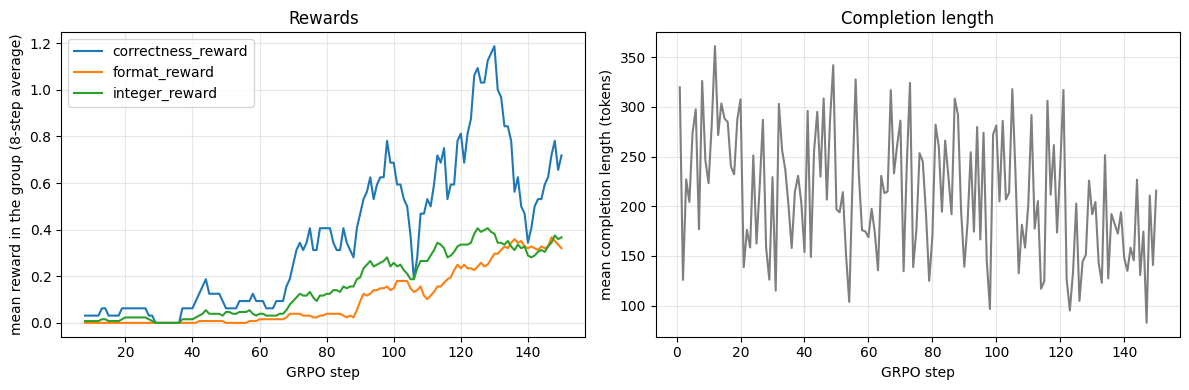

In [11]:
def reward_curve(log_history, key_part):
    """Per-step mean of one reward function. TRL 0.22 logs it as rewards/<name>/mean."""
    steps, values = [], []
    for entry in log_history:
        for key, value in entry.items():
            if key.startswith("rewards/") and key_part in key and key.endswith("/mean"):
                steps.append(entry["step"])
                values.append(value)
    return np.array(steps), np.array(values)


def smooth(values, window=8):
    """Moving average, so that the per-step noise of 8 samples does not hide the trend."""
    return np.convolve(values, np.ones(window) / window, mode="valid") if len(values) >= window else values


history = trainer.state.log_history
fig, (ax_reward, ax_len) = plt.subplots(1, 2, figsize=(12, 4))
for fn in REWARD_FUNCS:
    steps, values = reward_curve(history, fn.__name__)
    smoothed = smooth(values)
    ax_reward.plot(steps[len(steps) - len(smoothed):], smoothed, label=fn.__name__)
ax_reward.set(xlabel="GRPO step", ylabel="mean reward in the group (8-step average)", title="Rewards")
ax_reward.legend()
lengths = [(e["step"], e["completions/mean_length"]) for e in history if "completions/mean_length" in e]
ax_len.plot(*zip(*lengths), color="tab:gray")
ax_len.set(xlabel="GRPO step", ylabel="mean completion length (tokens)", title="Completion length")
for axis in (ax_reward, ax_len):
    axis.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### After training

The same held-out problems are decoded with the trained adapter. `model.load_lora` returns the request object vLLM needs to apply the saved adapter during decoding. The reward only pays for answers inside the tag, so the tagged accuracy and the format rate are what training should move most.

In [12]:
after = evaluate(test_data, lora_request=model.load_lora("grpo_lora"))
print(f"{'':12}{'accuracy (any)':>16}{'accuracy (tag)':>16}{'format rate':>13}")
for name, result in (("before", before), ("after", after)):
    print(f"{name:12}{result['accuracy_any']:>16.2f}{result['accuracy_tag']:>16.2f}{result['format_rate']:>13.2f}")
print("\nexample completion after GRPO:\n", after["example"][:500])

              accuracy (any)  accuracy (tag)  format rate
before                  0.57            0.00         0.00
after                   0.52            0.45         0.90

example completion after GRPO:
 <reasoning>
First, we need to calculate the total cost of the canvas bags. Tara bought 8 packs of 5 canvas bags for $4 each, so the total cost is 8 * 5 * $4 = $160. Next, we need to calculate the total revenue from selling the canvas bags. Tara sold them at a craft fair for $8 each, so the total revenue is 8 * $8 = $64. Finally, we can calculate the profit by subtracting the total cost from the total revenue, which is $64 - $160 = -$96. Since the result is negative, it means that Tara lost money


### The advantages of one group

To see the mechanism, we sample one held-out prompt `NUM_GENERATIONS` times at temperature 1 with the trained adapter, score the samples with the three rewards and compute the advantages two ways: divided by the group's standard deviation, as GRPO does, and centred only, as Dr. GRPO proposes.

In [13]:
def group_advantages(rewards, divide_by_std=True, eps=1e-4):
    """Group-relative advantages: centred rewards, divided by the group std unless divide_by_std is False."""
    centred = rewards - rewards.mean()
    return centred / (rewards.std() + eps) if divide_by_std else centred


example = test_data[1]
sampler = SamplingParams(temperature=1.0, n=NUM_GENERATIONS, max_tokens=MAX_COMPLETION_LENGTH, seed=SEED)
group = model.fast_generate([chat_text(example)], sampling_params=sampler, lora_request=model.load_lora("grpo_lora"))[0].outputs
completions = [[{"role": "assistant", "content": out.text}] for out in group]
answers = [example["answer"]] * len(completions)
rewards = np.zeros(len(completions))
for fn in REWARD_FUNCS:
    rewards += np.array(fn(prompts=None, completions=completions, answer=answers))

print("question:", example["prompt"][1]["content"][:150], "... answer:", example["answer"])
print(f"\n{'sample':>6}{'reward':>8}{'A (GRPO)':>10}{'A (Dr. GRPO)':>14}   extracted answer")
for i, (r, a, a_dr) in enumerate(zip(rewards, group_advantages(rewards), group_advantages(rewards, divide_by_std=False))):
    print(f"{i:>6}{r:>8.1f}{a:>10.2f}{a_dr:>14.2f}   {extract_xml_answer(completions[i][0]['content'])[:20]}")
print(f"\ngroup std of the rewards: {rewards.std():.3f}")

question: Mary is making ice cubes with fruit frozen in them for a cocktail party. She makes some strawberry cubes, and a number of blueberry cubes equal to 5 t ... answer: 96

sample  reward  A (GRPO)  A (Dr. GRPO)   extracted answer
     0     0.5     -0.55         -0.62   \( 5x - 4 \)
= \( 5 
     1     3.0      1.65          1.88   96
     2     1.0     -0.11         -0.12   100
     3     3.0      1.65          1.88   96
     4     0.0     -0.99         -1.12   To find out how many
     5     1.0     -0.11         -0.12   90
     6     0.0     -0.99         -1.12   \( X + 5X - 4 = 116 
     7     0.5     -0.55         -0.62   \( S = 16 \)

The nu

group std of the rewards: 1.139


**What to notice**

All three rewards read the number inside the `<answer>` tag, and the model starts without the tag, so the three curves sit near zero until sampling starts to produce it and then rise together. Correctness, worth up to 2.0, climbs furthest; format and integer, worth 0.5 each, follow below it. With one prompt per step the curves are noisy, and a run of hard prompts shows as a dip. 150 steps is a short run, which is why real runs take hundreds or thousands of steps on many more prompts. In the table the tagged accuracy and the format rate move most while the lenient accuracy moves less: the model mostly learns to put the number it already finds into the tag. In the advantage table a group where every sample earns the same reward has advantages of zero and teaches nothing in that step, and dividing by the standard deviation inflates the advantages of a group with one odd sample, which is the difficulty bias Dr. GRPO removes.

### Save and reload the adapter

`save_lora` wrote the adapter to `grpo_lora` in PEFT's format (`adapter_config.json` and `adapter_model.safetensors`). The same directory loads back into vLLM through `load_lora`, which is how the evaluation above used it. As a last check we reload it once more and decode one problem.

In [14]:
adapter_bytes = sum(os.path.getsize(os.path.join("grpo_lora", f)) for f in os.listdir("grpo_lora"))
print(f"adapter size on disk: {adapter_bytes / 1e6:.1f} MB")

reloaded_lora = model.load_lora("grpo_lora")
check = test_data[2]
output = model.fast_generate([chat_text(check)], sampling_params=greedy, lora_request=reloaded_lora)[0].outputs[0].text
print("question:", check["prompt"][1]["content"][:200])
print("reference answer:", check["answer"], "| extracted:", extract_xml_answer(output))
print("\n" + output[:500])

adapter size on disk: 37.0 MB
question: Britany records 18 4-minute TikTok videos each week. She spends 2 hours a week writing amateur songs to sing on TikTok, and 15 minutes six days a week doing her makeup before filming herself for TikTo
reference answer: 1128 | extracted: 840

<reasoning>
Britany spends 2 hours a week writing amateur songs, which is 2 * 60 = 120 minutes. She also spends 15 minutes six days a week doing her makeup, which is 15 * 6 = 90 minutes. In total, she spends 120 + 90 = 210 minutes on TikTok each week. Since there are 4 weeks in a month, Britany spends 210 * 4 = 840 minutes on TikTok in a month.
</reasoning>
<answer>
840
</answer>


## Summary

- GRPO needs no critic and no reward model: a group of samples per prompt gives the baseline, and code gives the reward.
- vLLM sampling, 4-bit loading, a rank-16 LoRA and 8-bit optimizer states make `NUM_GENERATIONS` completions per step affordable on a T4.
- Every reward here needs the answer tag, so all three stay flat until the model emits it and then rise together; groups with identical rewards teach nothing.
- `beta`, `loss_type` and `scale_rewards` are the knobs the current recipes argue about: the KL term, the token normalisation and the division by the group std.

## Exercises

1. **Group size.** Set `NUM_GENERATIONS = 4` and then `16` (lower `GPU_MEMORY_UTILIZATION` or `MAX_COMPLETION_LENGTH` if memory runs out). Compare the seconds per step and how noisy the reward curves are.
2. **The KL term.** Set `BETA = 0.04`. TRL then loads a reference model and logs a `kl` column. Compare the completion-length curve and the time per step with the run above.
3. **Dr. GRPO.** Set `scale_rewards="none"` in `GRPOConfig` and retrain. Compare the advantage table for the same prompt and the correctness curve.
4. **Reward shaping.** Remove `format_reward` from `REWARD_FUNCS`. Compare the tagged accuracy and the format rate after 150 steps with the run above.

## Further Reading

- [Shao et al., 2024. DeepSeekMath: Pushing the Limits of Mathematical Reasoning in Open Language Models](https://arxiv.org/abs/2402.03300)
- [Liu et al., 2025. Understanding R1-Zero-Like Training: A Critical Perspective](https://arxiv.org/abs/2503.20783)
- [Yu et al., 2025. DAPO: An Open-Source LLM Reinforcement Learning System at Scale](https://arxiv.org/abs/2503.14476)
- [Cobbe et al., 2021. Training Verifiers to Solve Math Word Problems](https://arxiv.org/abs/2110.14168)
- [Dettmers et al., 2023. QLoRA: Efficient Finetuning of Quantized LLMs](https://arxiv.org/abs/2305.14314)

### Contributed by: Mohamed Eltayeb